# Лабораторная работа №3. Транскрипция (G2P)

**Выполнила:** Перминова Анастасия, группа M4221

**Цель работы:** разработать модуль преобразования графем в фонемы (G2P) для русского языка и подготовить фонетическую транскрипцию корпуса RUSLAN для обучения акустической модели.

**Структура отчёта**

| Этап | Суть| Скрипт |
|---|---|---|
| 1 | Предобработка: слова ↔ фонемы из `.TextGrid`, словарь произношений | `prepare_lexicon.py` |
| 2 | Разведочный анализ фонемного инвентаря | `eda.py` |
| 3 | Модуль транскрипции `G2P` | `g2p.py` |
| 4 | Метаданные «текст – фонемы» для работы №4 | `prepare_metadata_phones.py`, `eda.check_metadata` |

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

import eda

%matplotlib inline
pd.set_option("display.max_colwidth", 80)

---
## Этап 1. Предобработка фонетических данных

Разметка `RUSLAN_22050_align_v2/*.TextGrid` (результат лабораторной работы №2) содержит два уровня: слова и фонемы. Нужно их сопоставить. На выходе получаем три таблицы:

* `data/tokens_phones.csv`: по строке на токен, без пауз, для обучения транскриптора;
* `data/tokens_phones_sil.csv`: то же, но с токенами пауз `<SIL>` на своих местах, для акустической модели;
* `data/lexicon.csv`: словарь `token | phones | frequency`, собранный **только по train-части**, чтобы не подмешивать в словарь test.

Четвертый артефакт, `data/russian_mfa.dict`, это скачанный оригинальный словарь MFA.

### Скрипт `prepare_lexicon.py`:

| Функция | Суть |
|---|---|
| `phones_of_token(phones, start, end)` | Собирает фонемы одного слова. Принадлежность определяем по середине интервала фонемы, а не по границам, потому что границы двух уровней могут расходиться. Метки приводятся к NFC, знак долготы `ː` убирается (в целевом инвентаре `phones_mfa.txt` его нет), пустая метка превращается в `<SIL>`. |
| `read_kept_ids(path)` | Читает идентификаторы предложений, которые прошли фильтр из лр №1. Выравнивание строилось по сырому тексту, и в нем есть предложения, которые нормализатор отбросил (например, с цифрами, аббревиатурами). |
| `read_alignment(align_root, keep, keep_sil)` | Читает все TextGrid и строит записи `id, token_id, token, phones, set`. Предложение с меткой `spn` удаляется целиком. Деление на `train`/`test`: test, если номер предложения делится на 5. При `keep_sil=True` паузы сохраняются как токен `<SIL>`. |
| `build_lexicon(rows)` | Считает частоты произношений каждого токена **только по train**. |
| `main()` | Записывает `tokens_phones.csv`, `tokens_phones_sil.csv` и `lexicon.csv`. |

### Проверка результата этапа:

In [3]:
tokens, lex, mfa_dict = eda.load_data()
eda.overview(tokens, lex, mfa_dict)


В tokens_phones: 19,777 текстов; 220,740 токенов

 {'train': 176164, 'test': 44576}

В lexicon: 39,293 слов, из которых 38,645 уникальные

В russian_mfa.dict: 452,401 слов



In [4]:
eda.check_tokens_files()

220740 273718 19777

spn: 0 | пустых phones: 0

<SIL> в tokens_phones: 0 
<SIL> в tokens_phones_sil: 52978

уникальных фонем: 55


* 220740: число строк в tokens_phones.csv, без пауз.
* 273718: число строк в tokens_phones_sil.csv, то же самое, но вместе с токенами `<SIL>`.
* 19777: число уникальных предложений (id) в tokens_phones.csv, оставшихся после фильтра лабораторной №1 и удаления предложений с spn.

Уникальных фонем 55, а не 56, потому что одно "место" занимает `<SIL>`.

In [5]:
tokens.head(10)

,id,token_id,token,phones,set
0,000000_RUSLAN,0,с,s̪,test
1,000000_RUSLAN,1,тревожным,t̪ rʲ ɪ v o ʐ n̪ ɨ m,test
2,000000_RUSLAN,2,чувством,tɕ u s̪ t̪ v ə m,test
3,000000_RUSLAN,3,берусь,bʲ ɪ r u sʲ,test
4,000000_RUSLAN,4,я,j a,test
5,000000_RUSLAN,5,за,z̪ ə,test
6,000000_RUSLAN,6,перо,pʲ ɪ r o,test
7,000001_RUSLAN,0,кого,k ɐ v o,train
8,000001_RUSLAN,1,интересуют,ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪,train
9,000001_RUSLAN,2,признания,p rʲ ɪ z̪ n̪ a ɲ e,train


In [6]:
lex.sample(10)

,token,phones,frequency
25276,представили,p rʲ ɪ t̪ s̪ t̪ a vʲ ɪ ʎ ɪ,1
16760,мужчина,m ʊ ɕ i n̪ ə,30
35117,узком,ʊ s̪ k ə m,2
8771,живых,ʐ ɨ v ɨ x,3
10908,изб,i s̪ p,1
421,аляповатый,ɐ ʎ ɪ p ɐ v a t̪ ɨ j,1
888,бабушкиной,b a b ʊ ʂ c ɪ n̪ ə j,1
32566,страшусь,s̪ t̪ r ɐ ʂ u sʲ,1
32600,строже,s̪ t̪ r o ʐ ɨ,1
30138,семидесятой,sʲ ɪ mʲ ɪ dʲ ɪ sʲ a t̪ ə j,2


В `tokens_phones.csv` не осталось `spn` и пустых транскрипций, токен `<SIL>` присутствует только в `tokens_phones_sil.csv`, число уникальных фонем показывает размер инвентаря после обработки.

---
## Этап 2. Разведочный анализ фонемного инвентаря

### 2.1. Какие фонемы представлены в корпусе, как они соотносятся с IPA

| Функция | Суть |
|---|---|
| `phone_inventory(tokens)` | Частота и доля каждой фонемы |
| `plot_phone_counts(inventory)` | Столбчатая диаграмма частот |
| `compare_with_ipa(inventory)` | Сравнение с таблицей IPA для русского языка. Перед сравнением `strip_notation` убирает дентальный диакритик MFA (`t̪` → `t`) |

In [7]:
inventory = eda.phone_inventory(tokens)
inventory

,count,share_%
phones,,
ɪ,100860,8.102
ə,94311,7.576
ɐ,65702,5.278
a,55660,4.471
t̪,54580,4.384
n̪,48601,3.904
j,48601,3.904
e,43592,3.502
s̪,41429,3.328


Всего фонем в корпусе: 55


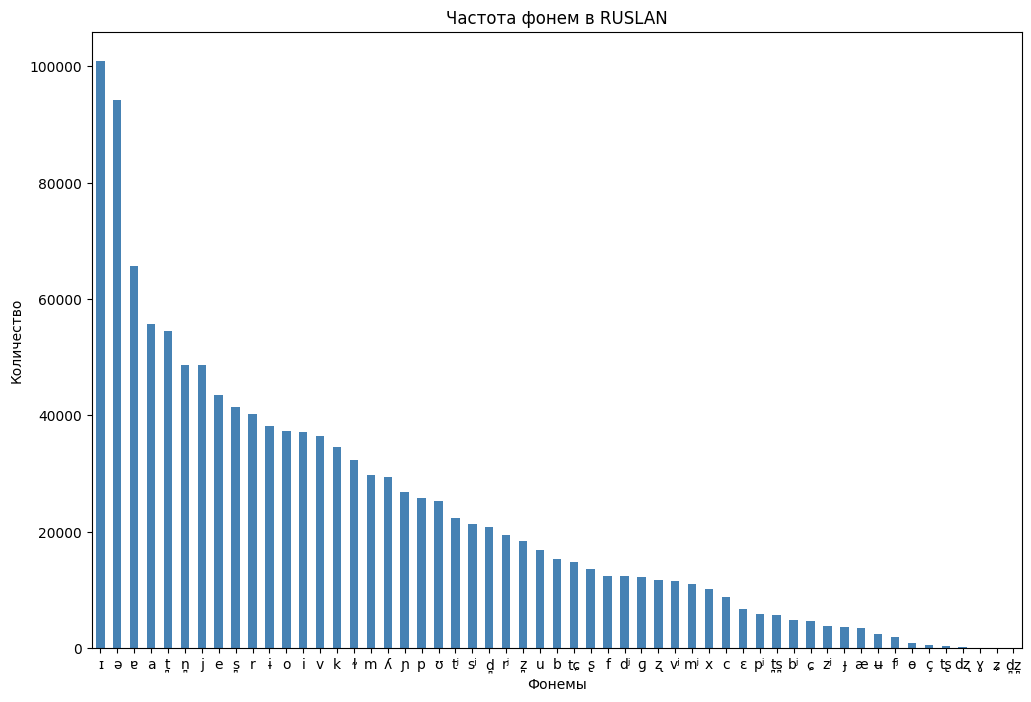

In [8]:
eda.plot_phone_counts(inventory)

Всего в корпусе представлено **55 разных фонем**.

Распределение довольно скошено: топ-10 фонем дают 47,7% всех вхождений, топ-20 дают 74,0%, 16 фонем встречаются реже 0,5%. Чаще всего встречаются редуцированные гласные: `ɪ` (8,10%), `ə` (7,58%), `ɐ` (5,28%). Редуцированные гласные составляют примерно 23% корпуса, а все 14 гласных вместе 42,4%.
Самые частые согласные: `t̪, n̪, j, s̪, r, v, k, ɫ`, по 2,6-4,4% каждая.

Почти четверть корпуса приходится на безударные гласные, поэтому главная трудность транскрипции в выборе между полным гласным и редуцированным. Для этого нужно знать ударение, которого в тексте нет.

In [9]:
eda.compare_with_ipa(inventory)

В корпусе: 55, на странице IPA: 59, совпадает: 47

Есть в корпусе, но нет в IPA: ['c', 'ç', 'ɕ', 'ɟ', 'ɫ', 'ɲ', 'ʎ', 'ʑ']

Есть в IPA, но нет в корпусе: ['dzʲ', 'dʑ', 'kʲ', 'l', 'lʲ', 'nʲ', 'tsʲ', 'xʲ', 'ɕː', 'ɡʲ', 'ɣʲ', 'ʑː']


Набор MFA близок к IPA, но не совпадает с ним: MFA отдельно выделяет дентальные варианты (`t̪ d̪ s̪ z̪ n̪`), палатализованные согласные записывает в нескольких вариантах (в том числе `c ɟ ç ʎ ɲ` для мягких `к г х л н`), а аффрикаты `ts`, `dz` представлены иначе, чем на странице IPA.

### 2.2. Длительности фонем

| Функция | Назначение |
|---|---|
| `read_durations(align, cache)` | Длительности всех фонем из TextGrid в мс (без пауз и `spn`) |
| `duration_tables(d, limit)` | Статистика (n, mean, std, median, CV = std/mean) со всеми интервалами и без выбросов длиннее 500 мс |
| `outlier_examples(d, limit, n)` | Фонемы, чаще всего дающие выбросы и случайные предложения |
| `outlier_effect(stats, stats_clean)` | Как очистка от выбросов меняет среднее, std и CV выбранных фонем |
| `plot_mean_durations(d, stats_clean)` | Средние длительности по фонемам и самые вариативные фонемы |

In [10]:
d = eda.read_durations(cache="durations.pkl")
stats, stats_clean = eda.duration_tables(d)
stats_clean

Интервалов > 500 мс: 273 из 1423471 (0.019%), предложений: 223


,n,mean,std,median,cv
phone,,,,,
ɪ,115295,18.07,27.52,10.0,1.52
ʉ,2755,38.30,33.05,30.0,0.86
ə,108043,39.92,34.93,30.0,0.88
ɨ,43571,51.94,35.72,40.0,0.69
ɣ,30,54.67,28.62,45.0,0.52
ʊ,28749,59.99,35.63,50.0,0.59
d̪z̪,1,60.00,NaN,60.0,NaN
r,45767,62.33,27.83,60.0,0.45
ɐ,74932,64.09,21.35,60.0,0.33


In [11]:
eda.outlier_effect(stats, stats_clean)

с выбросами              без выбросов             
             mean    std    cv         mean    std    cv
phone                                                   
ɪ           20.35  65.75  3.23        18.07  27.52  1.52
ɫː         108.48  51.67  0.48       106.33  41.26  0.39
zʲ         103.29  28.30  0.27       103.15  26.79  0.26
i           70.31  41.37  0.59        70.17  40.39  0.58
t̪s̪       133.01  39.87  0.30       132.90  39.02  0.29

In [12]:
eda.outlier_examples(d, n=3)

Фонемы, чаще всего дающие выбросы:
phone
ɪ     222
i      10
v       7
ɐ       5
a       4
n̪      3
o       2
ɛ       2
p       2
ə       2

019109_RUSLAN: Можно сказать, что творчество Пушкина было победой чистого эстетизма над общественно-политическими тенденциями проповедничества и морализаторства в литературе.
   фонема «ɪ» с 9.00 с, длительность 790 мс

019125_RUSLAN: На смену этим четырем титанам пришел Антон Павлович Чехов – первый истинный европеец в русской литературе, занимавшийся исключительно художественным творчеством и не запятнавший себя никакими общественно-политическими выходками и фокусами.
   фонема «ɪ» с 12.14 с, длительность 1470 мс

019501_RUSLAN: (нет в метаданных)
   фонема «ɪ» с 3.62 с, длительность 1520 мс
   фонема «ɪ» с 5.62 с, длительность 1140 мс
   фонема «ɪ» с 7.26 с, длительность 1190 мс


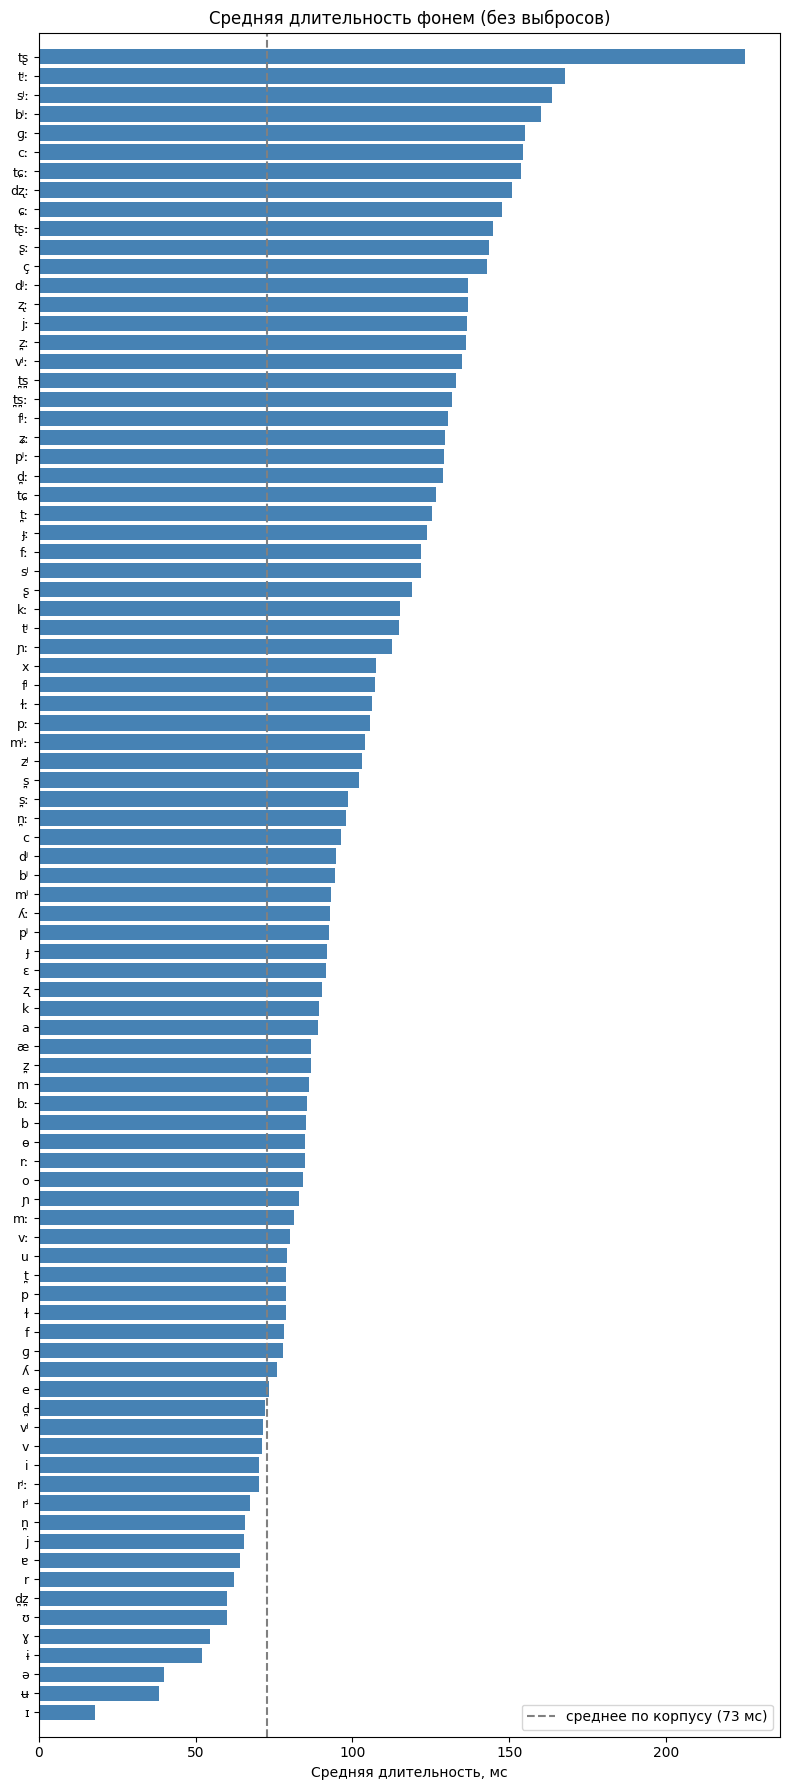

Средняя длительность по корпусу: 72.6 мс

Самые вариативные (n >= 100):
 phone
ɪ    1.52
ə    0.88
ʉ    0.86
ɨ    0.69
j    0.60


In [13]:
eda.plot_mean_durations(d, stats_clean)

Большая часть выбросов (интервалы > 500 мс) сосредоточена в одной фонеме: среди десяти самых «проблемных» фонем на редуцированную `ɪ` приходится 222 из 259 выбросов. Поэтому именно у `ɪ` эти выбросы сильнее всего увеличивают std и CV, а это одна из самых частых фонем корпуса.

Такие интервалы у гласной, скорее всего, сбой выравнивателя. Возможно безударная `ɪ` просто слабая, и выравниватель растягивает ее на соседнюю паузу или шум. В выборке примеров некоторые предложений отсутствуют в нормализованных метаданных, а значит, удаляются фильтром. Для описания длительностей используется статистика без выбросов.

**Средние длительности**

* Редуцированные и неоднозначные гласные самые короткие: `ɪ` 18 мс, `ʉ` 38 мс, `ə` 40 мс и т.д. Полные гласные заметно длиннее: `i` 70 мс, `e` 74 мс, `u` 79 мс и т.д. Это согласуется с фонетикой: безударные гласные укорачиваются и редуцируются.
* Сонорные и `j` короткие (`r` 62 мс, `j` 65 мс, `n̪` 66 мс, `rʲ` 67 мс); взрывные и звонкие щелевые средние по длительности (70–100 мс); шипящие, свистящие и аффрикаты самые долгие: `tɕ` 127 мс, `t̪s̪` 133 мс, а `ɕ` (щ) 148 мс - самая долгая из частых фонем.
* Мягкие согласные, как правило, длиннее твердых пар: `tʲ` 115 мс против `t̪` 79 мс, `fʲ` 107 мс против `f` 78 мс.
* Средняя длительность по корпусу: 72,6 мс.

**Вариативность (CV = std / mean).**

* Самый вариативный `ɪ`: CV = 1,52 (даже после удаления выбросов > 500 мс), далее идут `ə` (0,88), `ʉ` (0,86), `ɨ` (0,69).
* Самые стабильные - долгие щелевые и аффрикаты: `sʲː` 0,19, `ɕ` 0,21, `tɕ` 0,25 мс.

Длительности в корпусе разнородны: у редуцированных гласных большой разброс, поэтому модель должна будет опираться на контекст и на позицию относительно ударения.

### 2.3. Самые редкие фонемы

In [14]:
eda.rare_phones(inventory, lex, n=10)

,count,share_%,examples (train lexicon)
phones,,,
d̪z̪,1,0.000,зальцбурге
ʑ,19,0.002,"зажженными, уезжал, дождевых, дребезжал, езжу"
ɣ,23,0.002,"бухгалтер, ого, сверхсрочников, сверхсрочники, бухгалтера"
dʐ,229,0.018,"пиджак, джинсах, джинсы, пиджаке, джон"
tʂ,283,0.023,"лучше, лучшие, лучших, лучшее, сумасшедший"
ç,503,0.040,"стихи, хиггинс, эпохи, духе, слухи"
ɵ,955,0.077,"все, майор, районе, ньюйоркер, майора"
fʲ,1877,0.151,"кофе, любовь, фима, шофер, впервые"
ʉ,2406,0.193,"люди, чуть, людей, союзе, надеюсь"


Редкие фонемы можно оставить как есть (если они есть в целевом инвентаре), либо слить с близкой фонемой, если число примеров слишком мало для обучения.

### 2.4. Слова вне словаря (OOV)

| Функция | Суть |
|---|---|
| `oov_table(tokens, lex, mfa_dict)` | Доля OOV по токенам и типам для всего корпуса, train и test относительно `russian_mfa.dict`, `lexicon.csv` и объединения обоих |
| `oov_details(tokens, mfa_dict)` | Сколько типов и токенов нет в словаре MFA, как часто они встречаются, примеры |

In [15]:
eda.oov_table(tokens, lex, mfa_dict)

,часть,словарь,OOV токенов,% токенов,OOV типов,% типов
0,весь корпус,russian_mfa.dict,13511,6.12,7588,17.23
1,весь корпус,lexicon.csv,5792,2.62,5393,12.25
2,весь корпус,ни в одном,1258,0.57,1209,2.75
3,train,russian_mfa.dict,10706,6.08,6379,16.51
4,train,lexicon.csv,0,0.00,0,0.00
5,train,ни в одном,0,0.00,0,0.00
6,test,russian_mfa.dict,2805,6.29,2064,12.91
7,test,lexicon.csv,5792,12.99,5393,33.73
8,test,ни в одном,1258,2.82,1209,7.56


In [16]:
eda.oov_details(tokens, mfa_dict)

Типов в корпусе: 44038, нет в MFA: 7588 (17.2%)
Токенов с такими словами: 13511 из 220740 (6.12%)
Из них встречаются 1 раз: 5800
['фотокорам', 'бабичев', 'панибратским', 'проффера', 'полянского', 'рейгану', 'начитанной', 'окунешься', 'содержательного', 'дымчатая', 'пленэра', 'линецкого', 'рафальский', 'десятикратном', 'домье', 'заваленным', 'взъёбка', 'буковского', 'наводящие', 'легальная', 'кружевного', 'неорганизованных', 'атлетическом', 'зюссом', 'невыразительности', 'прагматических', 'коржавина', 'отработана', 'стремянной', 'подредактируем']


Относительно `russian_mfa.dict` вне словаря 13 511 токенов (6,1%) и 7 588 типов (17,2%): отсутствующие слова редкие, около 76% таких типов (5 800) встречаются один раз, а в случайной выборке это в основном словоформы обычных слов, фамилии и заимствования или просторечные слова, так что словарь MFA может быть неполон по словоформам. Относительно `lexicon.csv`, построенного только по train, вне словаря 5 792 токена (13%) и 5 393 типа (33,7%) из test. Словари дополняют друг друга: из 5 792 токенов вне лексикона 4 534 (около 78%) есть в MFA, а из 2 805 токенов вне MFA 1 547 (около 55%) есть в лексиконе, поэтому токенов, отсутствующих в обоих словарях только 1 258.

### 2.5. Как разметка отработала на примерах, удаляемых фильтром

| Функция | Суть |
|---|---|
| `filter_funnel(tokens)` | Сколько предложений убрано фильтром лабы №1 и сколько из-за `spn` |
| `missing_textgrids(tokens)` | Предложения, прошедшие фильтр, но без TextGrid |
| `find_suspicious_words(tokens)` | В удаленных предложениях ищет сокращения, слова с цифрами и аббревиатуры и берет их фонемы из разметки |
| `suspicious_summary(susp)` | Для каждого типа: сколько слов получили `spn`, а сколько транскрипцию |
| `fake_transcriptions(susp)` | Примеры слов, которым выравниватель выдал транскрипцию вместо `spn` |

In [17]:
eda.filter_funnel(tokens)
missing = eda.missing_textgrids(tokens)

В исходном корпусе: 22200
Удалено фильтром лр 1: 441
Удалено из-за spn (этап 1 данной лр): 1982
Осталось в tokens_phones.csv: 19777
Файлов TextGrid: 22199; прошли фильтр лабы 1, но без TextGrid: ['005321_RUSLAN']


In [18]:
susp = eda.find_suspicious_words(tokens)
eda.suspicious_summary(susp)

  0%|          | 0/441 [00:00<?, ?it/s]

spn                         spn  есть транскрипция
kind                                              
нет гласных (аббревиатура)  292                 26
сокращение                    0                  7
цифры                         4                  0


In [19]:
eda.fake_transcriptions(susp, n=10)

,id,word,kind,phones,spn
0,000993_RUSLAN,кпсс,нет гласных (аббревиатура),k r ə f ɨ s̪,False
1,000994_RUSLAN,кпсс,нет гласных (аббревиатура),k r ə f ɨ s̪,False
2,001022_RUSLAN,мтс,нет гласных (аббревиатура),mʲ ɪ t̪ s̪,False
3,001256_RUSLAN,кпсс,нет гласных (аббревиатура),k r ə f ɨ s̪,False
4,001257_RUSLAN,г,сокращение,ɡ ɛ,False
5,001986_RUSLAN,г,сокращение,ɡ ɛ,False
6,002008_RUSLAN,г,сокращение,ɡ ɛ,False
7,002153_RUSLAN,тов,сокращение,t̪ ə f,False
12,005914_RUSLAN,вмк,нет гласных (аббревиатура),v mʲ k,False
13,005914_RUSLAN,вмк,нет гласных (аббревиатура),v mʲ k,False


Часть таких слов выравниватель пометил `spn` (такие предложения удаляются на этапе 1), но часть получила выдуманную транскрипцию (например, "квн" -

`[c ɪ ɫ ɐ v o n̪]`). Фильтр из первой лабораторной был нужен: без него в обучающие данные попали бы неправильные пары «слово – фонемы».

### 2.6. Омографы и ударение

Ударение в корпусе явно не размечено, но прослеживается по видам гласных.

| Функция | Суть |
|---|---|
| `stress_pos(phones)` | Номер слога с полным гласным, то есть предполагаемое ударение |
| `homograph_candidates(lex)` | Слова с вариативными позициями ударения в `lexicon.csv`и «устойчивые» кандидаты (редкий вариант ≥ 5 раз и ≥ 10% употреблений) |
| `show_dictionary_variants(words, lex, mfa_dict)` | Варианты произношения слов в `lexicon.csv` с частотами и в `russian_mfa.dict` |
| `mfa_variants_report(homographs, mfa_dict)` | Есть ли у кандидатов обе позиции ударения в словаре MFA |
| `show_contexts(tokens, words)` | Предложения, где слово получило каждый вариант ударения |
| `vowel_variants(lex)` | Слова, у которых варианты различаются гласными (омографы и служебные слова: *на, что, то, из*) |

In [20]:
all_h, robust = eda.homograph_candidates(lex)
robust.head(15)

Многосложных слов с определимым ударением: 25811
С разными позициями ударения: 128
Кандидатов в омографы (после порогов): 22


,variants,total,minor,minor_share
token,,,,
слова,2,72,24,0.333
дела,2,42,20,0.476
стоит,2,43,20,0.465
окна,2,38,15,0.395
лица,2,31,12,0.387
руки,2,35,11,0.314
виду,2,24,9,0.375
дома,2,83,9,0.108
двери,2,37,9,0.243


In [21]:
top_words = list(robust.index[:4])
eda.show_dictionary_variants(top_words, lex, mfa_dict)


=== слова ===
lexicon.csv:
     phones  frequency
s̪ ɫ ɐ v a         48
s̪ ɫ o v ə         24
russian_mfa.dict: ['s̪ ɫ o v ə', 's̪ ɫ ɐ v a']

=== дела ===
lexicon.csv:
   phones  frequency
dʲ ɪ ɫ a         22
dʲ e ɫ ə         20
russian_mfa.dict: ['dʲ e ɫ ə', 'dʲ ɪ ɫ a']

=== стоит ===
lexicon.csv:
       phones  frequency
s̪ t̪ o ɪ t̪         23
s̪ t̪ ɐ i t̪         20
russian_mfa.dict: ['s̪ t̪ o ɪ t̪', 's̪ t̪ ɐ i t̪']

=== окна ===
lexicon.csv:
   phones  frequency
ɐ k n̪ a         23
o k n̪ ə         15
russian_mfa.dict: ['o k n̪ ə', 'ɐ k n̪ a']


In [22]:
eda.mfa_variants_report(robust, mfa_dict)

Кандидатов: 22
  нет в словаре MFA:                1
  в словаре MFA >1 позиции ударения: 21
  в словаре MFA 1 позиция:           0


In [23]:
eda.show_contexts(tokens, list(robust.index[:3]), n=3)


======== слова ========

[ударение на слоге 1] s̪ ɫ o v ə  (32 раз)
   ни единого слова
   лагерная охрана не породила видных мастеров слова
   я заметил что все избегают слова мафия

[ударение на слоге 2] s̪ ɫ ɐ v a  (54 раз)
   и вот пытаюсь найти слова
   редакция слова и дела занимала пять комнат
   эти слова прозвучали как цитата

======== дела ========

[ударение на слоге 1] dʲ e ɫ ə  (25 раз)
   я говорил что лев толстой по сути дела обыватель
   редакция слова и дела занимала пять комнат
   кроме всего прочего редактор слова и дела звонил нашим авторам

[ударение на слоге 2] dʲ ɪ ɫ a  (28 раз)
   дела мои зашли в тупик
   увы дела в редакции шли не лучшим образом
   с административными кадрами дела обстояли значительно хуже

======== стоит ========

[ударение на слоге 1] s̪ t̪ o ɪ t̪  (29 раз)
   стоит мне приобрести что нибудь в кредит и эту штуку тотчас же уценивают
   стоит ли комментировать этот зловещий пошлый и безграмотный документ
   об этом человеке стоит рассказать п

In [24]:
vv = eda.vowel_variants(lex)
vv.head(10)

Слов, у которых гласные произносятся по-разному (редкий вариант не реже 5 раз и не реже 10% употреблений): 65; Токенов train, где стоит не самый частотный вариант (на них метод «самый частотный вариант» ошибется): 2536 из 176164 (1.44% токенов train)


,variants,total,minor,minor_share
token,,,,
на,2,2377,856,0.360
все,2,935,354,0.379
что,2,1962,334,0.170
то,2,555,152,0.274
из,2,746,151,0.202
при,2,169,79,0.467
уже,2,258,46,0.178
до,2,254,31,0.122
русской,2,59,29,0.492


**Выводы по омографам:**

* Ударение в MFA не помечается отдельным символом, но его можно проследить по редукции гласных. Поэтому ударным слогом считался единственный нередуцированный гласный, а кандидатом в омограф слово, у которого в `lexicon.csv` встречаются разные позиции ударения. Односложные слова (на, что, то), у которых гласный меняется из-за редукции, а не ударения, при таком подходе отсекались.
* В просмотренных примерах результат верный в большинстве случаев. Единственная ошибка: «слова и дела».
* Решение «взять самый частотный вариант» заведомо ошибется на токенах с редким вариантом произношения.
* Састь расхождений вызвана не омографией, а переменчивой редукцией служебных слов, которую словарь тоже не различает.
* словарь MFA в основном содержит оба варианта произношения для омографов (но выбрать между ними без контекста не получится).

### 2.7. Целевой список фонем и приведение к нему

In [25]:
eda.compare_with_target(d, inventory)
eda.long_consonants_share(d)

Целевой список: 55 | сырые TextGrid: 88 | tokens_phones.csv: 55

Сырые TextGrid, но нет в целевом: ['bʲː', 'bː', 'cː', 'dʐː', 'dʲː', 'd̪ː', 'fʲː', 'fː', 'jː', 'kː', 'mʲː', 'mː', 'n̪ː', 'pʲː', 'pː', 'rʲː', 'rː', 'sʲː', 's̪ː', 'tɕː', 'tʂː', 'tʲː', 't̪s̪ː', 't̪ː', 'vʲː', 'vː', 'z̪ː', 'ɕː', 'ɟː', 'ɡː', 'ɫː', 'ɲː', 'ʂː', 'ʎː', 'ʐː', 'ʑː']
tokens_phones.csv, но нет в целевом: нет
Целевой, но нет в tokens_phones.csv: нет
Интервалов с долгой фонемой: 16527 из 1423471 (1.16%)


Приведение корпусной разметки к целевому списку выполнено еще на этапе 1:

1. нормализация Юникода (NFC);
2. удаление знака долготы `ː`: долгие согласные в целевом списке отсутствуют, поэтому «долгая» фонема сводится к краткой;
3. замена пустой метки на `<SIL>`, удаление предложений с `spn`.

После этого все фонемы `tokens_phones.csv` принадлежат целевому набору.

---
## Этап 3. Модуль транскрипции `G2P`

Решение комбинирует словари и модель на правилах для OOV-слов. Порядок принятия решения для каждого токена:

1. **`lexicon.csv`** (train-часть корпуса): произношение, самое частотное для слова;
2. **`russian_mfa.dict`**: если слова нет в `lexicon.csv`, берется оригинальное произношение MFA (приведенное к целевому набору);
3. **`RuleG2P`**: если слова нет ни в одном словаре, произношение строится на правилах.

В данном случае *OOV* означает «слова нет в `lexicon.csv`» (но оно может быть в словаре MFA), *residual* означает «слова нет ни в одном словаре».

| Элемент | Суть |
|---|---|
| `load_lexicon`, `load_mfa_dict` | Читают словари. Для MFA отбрасываются записи с `spn` и слова не из кириллицы (`DICT_WORD`), произношения приводятся к целевому набору (`to_target`) |
| `G2P.__init__` | Строит словарь `pron`: сначала MFA, затем поверх него `lexicon.csv` (приоритет у корпуса), выбирая самый частотный вариант. Проверяет, что правила не выдают фонем вне целевого списка |
| `G2P.transcribe(tokens)` | Принимает список токенов, возвращает список списков фонем той же длины, `<SIL>` не меняет |
| `G2P.is_known(token)` | Есть ли слово хотя бы в одном словаре (граница между OOV и residual) |
| `StressPredictor` | Для слов без словаря предсказывает ударный слог по окончанию (до 5 букв), статистика собирается по словарным словам, у которых ударение восстановимо из формы гласной (`stressed_syllable`); при нехватке статистики в качестве ударного выбирается предпоследний слог |
| `RuleG2P` | Правила для слов вне словарей |
| `phone_error_rate`, `word_accuracy`, `calc_metrics`, `ablation`, `show_errors` | Метрики, оценка по группам слов, вклад правил, разбор худших примеров |

**Правила `RuleG2P`** применяются последовательно, каждое можно включать и выключать (`RULES`):

| Правило | Что делает |
|---|---|
| `spelling` | Орфографические упрощения: `сч, зч → щ`, `тч, дч → ч`, `стн → сн`, `здн → зн`, `вств → ств`, `-ого/-его → -ово/-ево`, `-ться/-тся → -ца` |
| `palatalization` | Мягкость согласных перед `я ё ю и е ь`, йотирование (`я е ё ю` после гласной, в начале слова и после ь/ъ дают `j` + гласную), `ч щ` всегда мягкие, `ж ш ц` всегда твёрдые |
| `voicing` | Оглушение на конце слова и ассимиляция по звонкости (перед глухим оглушается, перед звонким озвончается) |
| `reduction` | Выбор ударной гласной (ё, односложные слова, иначе `StressPredictor`), редукция безударных (`а, о → ɐ/ə`, `е, и → ɪ`, `я → ɪ/ə`, после шипящих `ɨ`), варианты ударных гласных по мягкости соседей (`æ`, `ɵ`, `ʉ`) |

### Результаты (вывод `python g2p.py`)

```
dropping 0 tokens without a transcription (0.00%)
train 176164 tokens / test 44576 tokens
lexicon: 38645 types, 613 with several pronunciations
russian_mfa.dict: 452277 words

Calculate metrics, training fold:
running text  PER 0.0075
in-vocabulary PER 0.0075  (176164 words, 100.0%)
OOV           PER nan  word accuracy nan  (0 words, 0.0%)
residual      PER nan  word accuracy nan  (0 words, 0.0%)  [in neither dictionary]

Calculate metrics, testing fold:
running text  PER 0.0156
in-vocabulary PER 0.0104  (38784 words, 87.0%)
OOV           PER 0.0363  word accuracy 0.8381  (5792 words, 13.0%)
residual      PER 0.1405  word accuracy 0.3029  (1258 words, 2.8%)  [in neither dictionary]
```

| Критерий | Порог | Результат (test) |
|---|---|---|
| PER на связном тексте | ≤ 0,025 | **0,0156** | 
| PER на остатке (нет ни в одном словаре) | ≤ 0,20 | **0,1405** |

Разбор долей на test (44 576 токенов):

* 87% токенов (38 784) найдены в `lexicon.csv`, PER = 0,0104;
* 13% токенов (5 792) отсутствуют в `lexicon.csv`; из них 4 534 (около 78%) нашлись в словаре MFA, PER на всей группе OOV = 0,0363;
* остаток 2,8 % токенов (1 258, около 22 % от OOV) не найден нигде, здесь только правила: PER = 0,1405.

Ненулевой PER на train (0,0075) при том, что все слова train есть в словаре - следствие выбора «самого частотного варианта»: так проявляется омография и переменная редукция.

### Вклад отдельных правил (вывод `python g2p.py --ablation`)

Правила включаются кумулятивно. «train PER» и «test residual PER» это PER самих правил на всех train-токенах и на residual-токенах test (словари не используются), последний столбец это итоговый PER на связном тексте test с полным модулем (словари + данная конфигурация правил).

| Конфигурация | train PER | test residual PER | test running text PER |
|---|---|---|---|
| naive letter → phone map | 0,5121 | 0,5444 | 0,0351 |
| + palatalization, iotation | 0,2901 | 0,3261 | 0,0246 |
| + voicing assimilation, devoicing | 0,2794 | 0,3147 | 0,0240 |
| + spelling rules | 0,2754 | 0,3083 | 0,0237 |
| + reduction, stress on penultimate | 0,2030 | 0,2139 | 0,0191 |
| + reduction, learned stress | 0,1280 | 0,1405 | 0,0156 |

Снижение PER на residual по шагам:

| Шаг | Δ residual PER |
|---|---|
| палатализация и йотирование | −0,2183 |
| озвончение и оглушение | −0,0114 |
| орфографические правила | −0,0064 |
| редукция, ударение на предпоследнем слоге | −0,0944 |
| редукция, ударение по окончаниям | −0,0734 |
| **итого** | **−0,4039** (с 0,5444 до 0,1405) |

**Выводы:**

* самый большой вклад (больше половины всего улучшения) дают **палатализация и йотирование**;
* **редукция гласных** вместе с ударением дает второй по величине вклад (−0,168), причем предсказание ударения по окончанием заметно лучше, чем просто «предпоследний слог» (−0,073 против нуля при той же редукции);
* озвончение и орфографические правила дают небольшие, но улучшения;
* без правил итоговый PER на тексте 0,0351 благодаря словарям, правила снижают его до 0,0156.

### Разбор ошибок (вывод `python g2p.py --errors`)

Худшие слова из residual test (фрагмент):

```
ньюфаундленд     6  ref: ɲ ʊ f a ʊ n̪ ʎ e n̪ t̪
                    hyp: ɲ j ʉ f ɐ u n̪ d̪ ʎ ɪ n̪ t̪
покосившаяся     5  ref: p ə k ɐ sʲ i f ʂ ɐ j a t̪ s̪ ə
                    hyp: p ə k ə sʲ ɪ f ʂ ɐ j æ sʲ ə
кипарисовую      5  ref: c ɪ p ɐ rʲ i s̪ ə v u j ʊ
                    hyp: c ɪ p ə rʲ ɪ s̪ o v ʊ j ʉ
фаршированную    4  ref: f ɐ r ʂ ɨ r ə v ə n̪ ʊ j ʊ
                    hyp: f ə r ʂ ɨ r o v ə n̪ n̪ ʊ j ʉ
расстегнута      4  ref: r ə sʲ tʲ ɪ ɡ n̪ ʊ t̪ ə
                    hyp: r ɐ s̪ s̪ tʲ e ɡ n̪ ʊ t̪ ə
октябрьскую      4  ref: ɐ c tʲ a b rʲ s̪ k ʊ j ʊ
                    hyp: o k tʲ ə b rʲ s̪ k ʊ j ʉ
четырнадцатое    4  ref: tɕ ɪ t̪ ɨ r n̪ ə t̪s̪ ɨ t̪ ə j ə
                    hyp: tɕ ɪ t̪ ɨ r n̪ a t̪ t̪s̪ ə t̪ ə j ɪ
```

Некоторые расхождения:
1. **Удвоенные согласные.** В эталоне долгота убрана, поэтому `нн`, `сс`, `тц` дают одну фонему, а правила выдают две подряд;
2. **Окончание `-ую`.** В безударной позиции эталон дает `ʊ j ʊ`, а правила `ʉ` для безударной `ю`;
3. **Заимствования и имена** (`ньюфаундленд`, `манхеттен`, `рамсдейл`): правила для русского плохо применяются.

---
## Этап 4. Метаданные для работы №4

`prepare_metadata_phones.py`

Из `tokens_phones_sil.csv` (слова и фонемы вместе с паузами) собираются два файла формата `id | normalized text | phones`:

* **`data/metadata_phones_gt.csv`** - эталонная разметка: для каждого предложения фонемы токенов из корпусной разметки склеиваются через пробел в порядке `token_id`, `<SIL>` на своих местах;
* **`data/metadata_phones.csv`** - предсказанная разметка: токены предложения пропускаются через `G2P.transcribe` (`G2P.from_files` с `lexicon.csv`, `russian_mfa.dict` и `phones_mfa.txt`), результат склеивается так же.

In [31]:
gt = pd.read_csv('../../data/metadata_phones_gt.csv', sep='|', header=None)
pred = pd.read_csv('../../data/metadata_phones.csv', sep='|', header=None)

In [39]:
gt.head(2)

,0,1,2
0,000000_RUSLAN,С тревожным чувством берусь я за перо.,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ r u sʲ j a z̪ ə pʲ ɪ r o <SIL>
1,000001_RUSLAN,Кого интересуют признания литературного неудачника?,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ z̪ n̪ a ɲ e ʎ ɪ tʲ ɪ r ɐ t̪ u...


In [40]:
pred.head(2)

,0,1,2
0,000000_RUSLAN,С тревожным чувством берусь я за перо.,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ r u sʲ j a z̪ ə pʲ ɪ r o <SIL>
1,000001_RUSLAN,Кого интересуют признания литературного неудачника?,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ z̪ n̪ a ɲ e ʎ ɪ tʲ ɪ r ɐ t̪ u...
